# 1. Import Libraries

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import MissingIndicator
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, roc_curve, confusion_matrix)
SEED = 591
pd.set_option("display.max_columns", 100)
pd.set_option("display.precision", 4)
print("Ready!")

Ready!


# 2. Load the Data and First Examination

In [56]:
df_raw = pd.read_csv('C:/Users/hainlidc/Documents/ISA 591/Data/loan_default_project.csv')
df = df_raw.copy()
print("Shape:", df.shape)
df.head()


Shape: (316972, 37)


,ID,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,title,dti,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,last_credit_pull_d,acc_now_delinq,hardship_flag,debt_settlement_flag
0,60943837,15175.0,36 months,16.55,537.64,D,D2,Maintenance,9 years,MORTGAGE,33000.0,Source Verified,Oct-2015,Fully Paid,debt_consolidation,Debt consolidation,23.56,Sep-2006,11.0,0.0,11376.0,46.1,24.0,f,INDIVIDUAL,2.0,0.0,"359 Miles Neck\r\nEast Fernando, ME 22690",4.0,680.0,684.0,1.0,5.0,Apr-2018,0.0,N,N
1,8955171,7500.0,36 months,11.99,249.08,B,B3,Professional,6 years,RENT,40000.0,Not Verified,Dec-2013,Charged Off,credit_card,Credit Fund,29.49,Sep-2002,11.0,0.0,7113.0,56.5,23.0,w,INDIVIDUAL,0.0,0.0,"630 James Corners\r\nNew Frederick, NV 93700",0.0,680.0,684.0,0.0,43.0,Oct-2016,0.0,N,N
2,10171435,12000.0,60 months,24.50,348.71,F,F3,Purchasing,4 years,MORTGAGE,70000.0,Source Verified,Jan-2014,Charged Off,debt_consolidation,Credit,18.50,Feb-1997,12.0,0.0,11699.0,83.6,48.0,w,INDIVIDUAL,6.0,0.0,"2082 Williams Green Apt. 298\r\nWest Ashley, W...",0.0,665.0,669.0,3.0,69.0,Feb-2017,0.0,N,N
3,8658237,10300.0,36 months,12.99,347.00,B,B4,Loan Compliance,10+ years,MORTGAGE,35000.0,Verified,Nov-2013,Charged Off,debt_consolidation,high interest relief,11.15,Aug-1996,11.0,0.0,1907.0,23.8,37.0,f,INDIVIDUAL,5.0,0.0,"78651 Sampson Motorway Suite 078\r\nChangfort,...",0.0,705.0,709.0,0.0,38.0,Mar-2019,0.0,N,N
4,6533627,12000.0,36 months,13.05,404.62,B,B5,Wells Fargo,2 years,RENT,85000.0,Verified,Aug-2013,Fully Paid,debt_consolidation,Credit Card Payoff,33.36,May-1994,21.0,0.0,21133.0,58.7,35.0,f,INDIVIDUAL,2.0,0.0,"375 Quinn Gateway Suite 800\r\nPort Cesarview,...",1.0,665.0,669.0,0.0,20.0,May-2017,0.0,N,N


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 316972 entries, 0 to 316971
Data columns (total 37 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ID                      316972 non-null  int64  
 1   loan_amnt               316972 non-null  float64
 2   term                    316972 non-null  object 
 3   int_rate                316972 non-null  float64
 4   installment             316972 non-null  float64
 5   grade                   316972 non-null  object 
 6   sub_grade               316972 non-null  object 
 7   emp_title               298521 non-null  object 
 8   emp_length              302316 non-null  object 
 9   home_ownership          316972 non-null  object 
 10  annual_inc              316972 non-null  float64
 11  verification_status     316972 non-null  object 
 12  issue_d                 316972 non-null  object 
 13  loan_status             316972 non-null  object 
 14  purpose             



**Things to notice:**
- Several columns that should be numbers or dates are stored as text (`object`): `term` (`" 36 months"`), `emp_length` (`"10+ years"`), `issue_d` and `earliest_cr_line` (`"Oct-2015"`). These are fixed in Section 3.
- Non-null counts below the row total mean missing values (for example, `mths_since_last_delinq`, `mort_acc`, `emp_title`, `emp_length`). These are handled in Section 6.

loan_status
Fully Paid     254793
Charged Off     62179
Name: count, dtype: int64

loan_status
Fully Paid     0.8038
Charged Off    0.1962
Name: proportion, dtype: float64


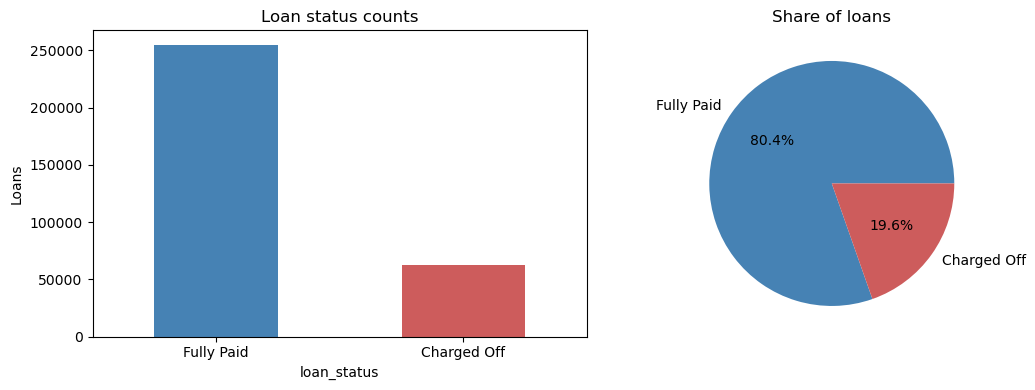

In [58]:
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

print(df["loan_status"].value_counts())
print()
print(df["loan_status"].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["loan_status"].value_counts().plot(kind="bar", ax=ax[0], color=["steelblue", "indianred"])
ax[0].set_title("Loan status counts"); ax[0].set_ylabel("Loans"); ax[0].tick_params(axis="x", rotation=0)
df["loan_status"].value_counts().plot(kind="pie", ax=ax[1], autopct="%1.1f%%",
                                      colors=["steelblue", "indianred"], ylabel="")
ax[1].set_title("Share of loans")
plt.tight_layout(); plt.show()



**Result:** about **19.6%** of loans charged off vs **80.4%** paid in full, a roughly 4:1 **class imbalance**.



# 3. Variable Roles, Data Types, and Leakage

In [59]:
print("Unique IDs:", df["ID"].nunique(), "of", len(df), "rows")
print("Rows sharing an ID with another row:", df["ID"].duplicated(keep=False).sum())

## Are rows with the same ID actually the same loan?
display(df[df["ID"].duplicated(keep=False)].sort_values("ID")
        [["ID", "loan_amnt", "int_rate", "issue_d", "annual_inc", "loan_status"]].head(6))

## True duplicates = identical in every column except ID
dup_mask = df.drop(columns="ID").duplicated()
print("Exact duplicate rows (ignoring ID):", dup_mask.sum())

Unique IDs: 311785 of 316972 rows
Rows sharing an ID with another row: 10303


,ID,loan_amnt,int_rate,issue_d,annual_inc,loan_status
133220,138582,3275.0,9.33,Oct-2007,62000.0,Fully Paid
122554,138582,8275.0,9.01,Oct-2007,120000.0,Fully Paid
196115,347611,7500.0,9.76,May-2008,38168.0,Fully Paid
313129,347611,7500.0,12.29,May-2008,500000.0,Fully Paid
134950,350345,7500.0,8.00,Jun-2008,48000.0,Fully Paid
62415,350345,7500.0,11.66,Jun-2008,61000.0,Fully Paid


Exact duplicate rows (ignoring ID): 87



- About 5,000 IDs are **reused by different loans**. The example rows show the same ID with different amounts, rates and incomes. So `ID` isn't a reliable key, and it says nothing about default risk → **drop it**.
- **87 rows** are exact duplicates of another row in every column except ID → **remove them**.

In [60]:
df = df.loc[~dup_mask].drop(columns="ID").reset_index(drop=True)
print("Shape after removing duplicates and ID:", df.shape)

Shape after removing duplicates and ID: (316885, 37)


In [61]:
print(pd.crosstab(df["debt_settlement_flag"], df["loan_status"]))
print()
print("hardship_flag levels:", df["hardship_flag"].unique())
print()
## last_credit_pull_d: the latest date LendingClub pulled the borrower's credit (often after the loan ended)
print(pd.crosstab(df["last_credit_pull_d"].str[-4:], df["loan_status"], normalize="index").round(3).tail(5))

loan_status           Charged Off  Fully Paid
debt_settlement_flag                         
N                           58002      254708
Y                            4175           0

hardship_flag levels: ['N']

loan_status         Charged Off  Fully Paid
last_credit_pull_d                         
2015                      0.038       0.962
2016                      0.429       0.571
2017                      0.322       0.678
2018                      0.135       0.865
2019                      0.074       0.926



**Results:**
- **`debt_settlement_flag`:** every loan with `Y` (about 4,200) charged off, and not one was paid in full. People only enter debt settlement *after* defaulting, so this is **data leakage**.
- **`hardship_flag`:** only one value (`N`), so it carries **no information**.
- **`last_credit_pull_d`:** the default rate swings wildly by year (about 43% in 2016 vs about 7% in 2019). This date is recorded *after* the loan was funded, so it's leakage too.

 A predictor must be known **on the day someone applies**. Anything recorded later makes the model look better than it really is.

In [62]:
df = df.drop(columns=["debt_settlement_flag", "last_credit_pull_d", "hardship_flag"])

**What this does:** drops the two leakage columns and the constant column identified above.

The other extra columns (`delinq_2yrs`, `fico_range_low/high`, `inq_last_6mths`, `mths_since_last_delinq`, `acc_now_delinq`) describe the borrower's credit file **at application**, so they're legitimate predictors and are kept.

In [63]:
df["term"] = df["term"].str.extract(r"(\d+)")[0].astype(int)

df["emp_length"] = (df["emp_length"]
                    .replace({"< 1 year": "0 years"})
                    .str.extract(r"(\d+)")[0]
                    .astype(float))

df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

df["zip_code"] = df["address"].str[-5:]
df["addr_state"] = df["address"].str.extract(r"\s([A-Z]{2})\s\d{5}$")[0]

display(df[["term", "emp_length", "issue_d", "earliest_cr_line", "zip_code", "addr_state"]].head())
print(df[["term", "emp_length", "issue_d", "earliest_cr_line"]].dtypes)

,term,emp_length,issue_d,earliest_cr_line,zip_code,addr_state
0,36,9.0,2015-10-01,2006-09-01,22690,ME
1,36,6.0,2013-12-01,2002-09-01,93700,NV
2,60,4.0,2014-01-01,1997-02-01,30723,WI
3,36,10.0,2013-11-01,1996-08-01,86630,CT
4,36,2.0,2013-08-01,1994-05-01,22690,SD


term                         int32
emp_length                 float64
issue_d             datetime64[ns]
earliest_cr_line    datetime64[ns]
dtype: object


fixes data types and creates two variables from `address`:
- `term`: `" 36 months"` → `36` (number)
- `emp_length`: `"< 1 year"` → 0, `"10+ years"` → 10, matching the variable description (0–10)
- `issue_d`, `earliest_cr_line`: text → real dates, so we can compute credit-history length later
- `zip_code`: last 5 characters of the address
- `addr_state`: the 2 capital letters before the zip (regex)



# 4. Summary Statistics and Frequency Tables

In [64]:
numeric_cols = df.select_dtypes(include="number").columns.drop("default")
categorical_cols = df.select_dtypes(include="object").columns.drop(["loan_status", "address"])

print("Numeric variables:", len(numeric_cols))
print("Categorical variables:", len(categorical_cols))

summary = df[numeric_cols].describe().T
summary["median"] = df[numeric_cols].median()
summary["skew"] = df[numeric_cols].skew()
summary.round(2)

Numeric variables: 20
Categorical variables: 11


,count,mean,std,min,25%,50%,75%,max,median,skew
loan_amnt,316885.0,14111.12,8355.17,500.00,8000.00,12000.00,20000.00,4.0000e+04,12000.00,0.78
term,316885.0,41.68,10.20,36.00,36.00,36.00,36.00,6.0000e+01,36.00,1.24
int_rate,316885.0,13.63,4.47,5.32,10.38,13.33,16.49,3.0990e+01,13.33,0.42
installment,316885.0,431.79,250.62,16.08,250.33,375.43,567.41,1.5338e+03,375.43,0.98
emp_length,302229.0,5.94,3.64,0.00,3.00,6.00,10.00,1.0000e+01,6.00,-0.21
annual_inc,316885.0,74235.85,62518.87,0.00,45000.00,64000.00,90000.00,8.7066e+06,64000.00,41.69
dti,316885.0,17.38,19.52,0.00,11.28,16.90,22.98,9.9990e+03,16.90,421.82
open_acc,316885.0,11.32,5.14,0.00,8.00,10.00,14.00,9.0000e+01,10.00,1.21
pub_rec,316885.0,0.18,0.54,0.00,0.00,0.00,0.00,8.6000e+01,0.00,18.78
revol_bal,316885.0,15817.27,20100.18,0.00,6024.00,11177.00,19601.00,1.2988e+06,11177.00,9.64



**What stands out:**
- `dti` has a max of **9,999**, an impossible debt-to-income value (placeholder or error).
- `annual_inc` runs from **$0 to $8.7 million** (median $64,000), so it's extremely right-skewed.
- `revol_util` reaches **892%**, while normal utilization is 0–~100%.
- Count variables (`pub_rec`, `delinq_2yrs`, `acc_now_delinq`) are mostly 0 with long tails (high skew).

These lead directly to the outlier decisions (Section 7) and the log transforms (later).

In [65]:
## Cardinality (number of levels) for each categorical variable
cardinality = df[categorical_cols].nunique().sort_values(ascending=False).to_frame("Unique levels")
cardinality

,Unique levels
emp_title,143505
title,40407
addr_state,54
sub_grade,35
purpose,14
zip_code,10
grade,7
home_ownership,6
verification_status,3
application_type,3



- `address` (~315k), `emp_title` (~143k) and `title` (~40k) are free text. Dummy-encoding them is impossible → group them or drop them.
- `sub_grade` (35) is an ordered version of `grade` (7) → convert it to a single number (A1 = 1 … G5 = 35).
- The date columns will become numeric features instead.

In [66]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    table = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Frequency")
    )
    table["Percent"] = (table["Frequency"] / len(df) * 100).round(2)

    n_levels = df[col].nunique(dropna=False)
    print(f"\n{col}  ({n_levels} levels)")
    if n_levels > 50:
        print("High cardinality - showing top 10 only")
        display(table.head(10))
    else:
        display(table)


grade  (7 levels)


,Category,Frequency,Percent
0,B,92806,29.29
1,C,84909,26.79
2,A,51566,16.27
3,D,50680,15.99
4,E,25155,7.94
5,F,9367,2.96
6,G,2402,0.76



sub_grade  (35 levels)


,Category,Frequency,Percent
0,B3,21266,6.71
1,B4,20507,6.47
2,C1,18923,5.97
3,C2,18127,5.72
4,B2,17961,5.67
5,B5,17633,5.56
6,C3,16998,5.36
7,C4,16234,5.12
8,B1,15439,4.87
9,A5,14971,4.72



emp_title  (143506 levels)
High cardinality - showing top 10 only


,Category,Frequency,Percent
0,NaN,18381,5.80
1,Teacher,3508,1.11
2,Manager,3425,1.08
3,Registered Nurse,1473,0.46
4,RN,1457,0.46
5,Supervisor,1445,0.46
6,Sales,1307,0.41
7,Project Manager,1213,0.38
8,Owner,1120,0.35
9,Driver,1058,0.33


... (16 outputs left out)


zip_code  (10 levels)


,Category,Frequency,Percent
0,70466,45602,14.39
1,30723,45352,14.31
2,22690,45323,14.30
3,48052,44637,14.09
4,00813,36590,11.55
5,29597,36469,11.51
6,05113,36318,11.46
7,11650,8955,2.83
8,93700,8930,2.82
9,86630,8709,2.75



addr_state  (54 levels)
High cardinality - showing top 10 only


,Category,Frequency,Percent
0,AP,11431,3.61
1,AE,11271,3.56
2,AA,11105,3.50
3,NV,5712,1.80
4,NJ,5688,1.79
5,MA,5672,1.79
6,WI,5666,1.79
7,LA,5654,1.78
8,SC,5653,1.78
9,TX,5650,1.78



**Things to notice:**
- `home_ownership`: `OTHER`, `NONE`, `ANY` add up to about 120 loans → group them into `OTHER`.
- `application_type`: 99.8% `INDIVIDUAL`.
- `purpose`: about 59% debt consolidation; `renewable_energy`, `educational` and `wedding` are each under 0.5% → group them into `other`.
- `emp_title`: thousands of one-off job titles → keep the top 15, plus `Other` and `Missing`.

# 5. Data Visualization


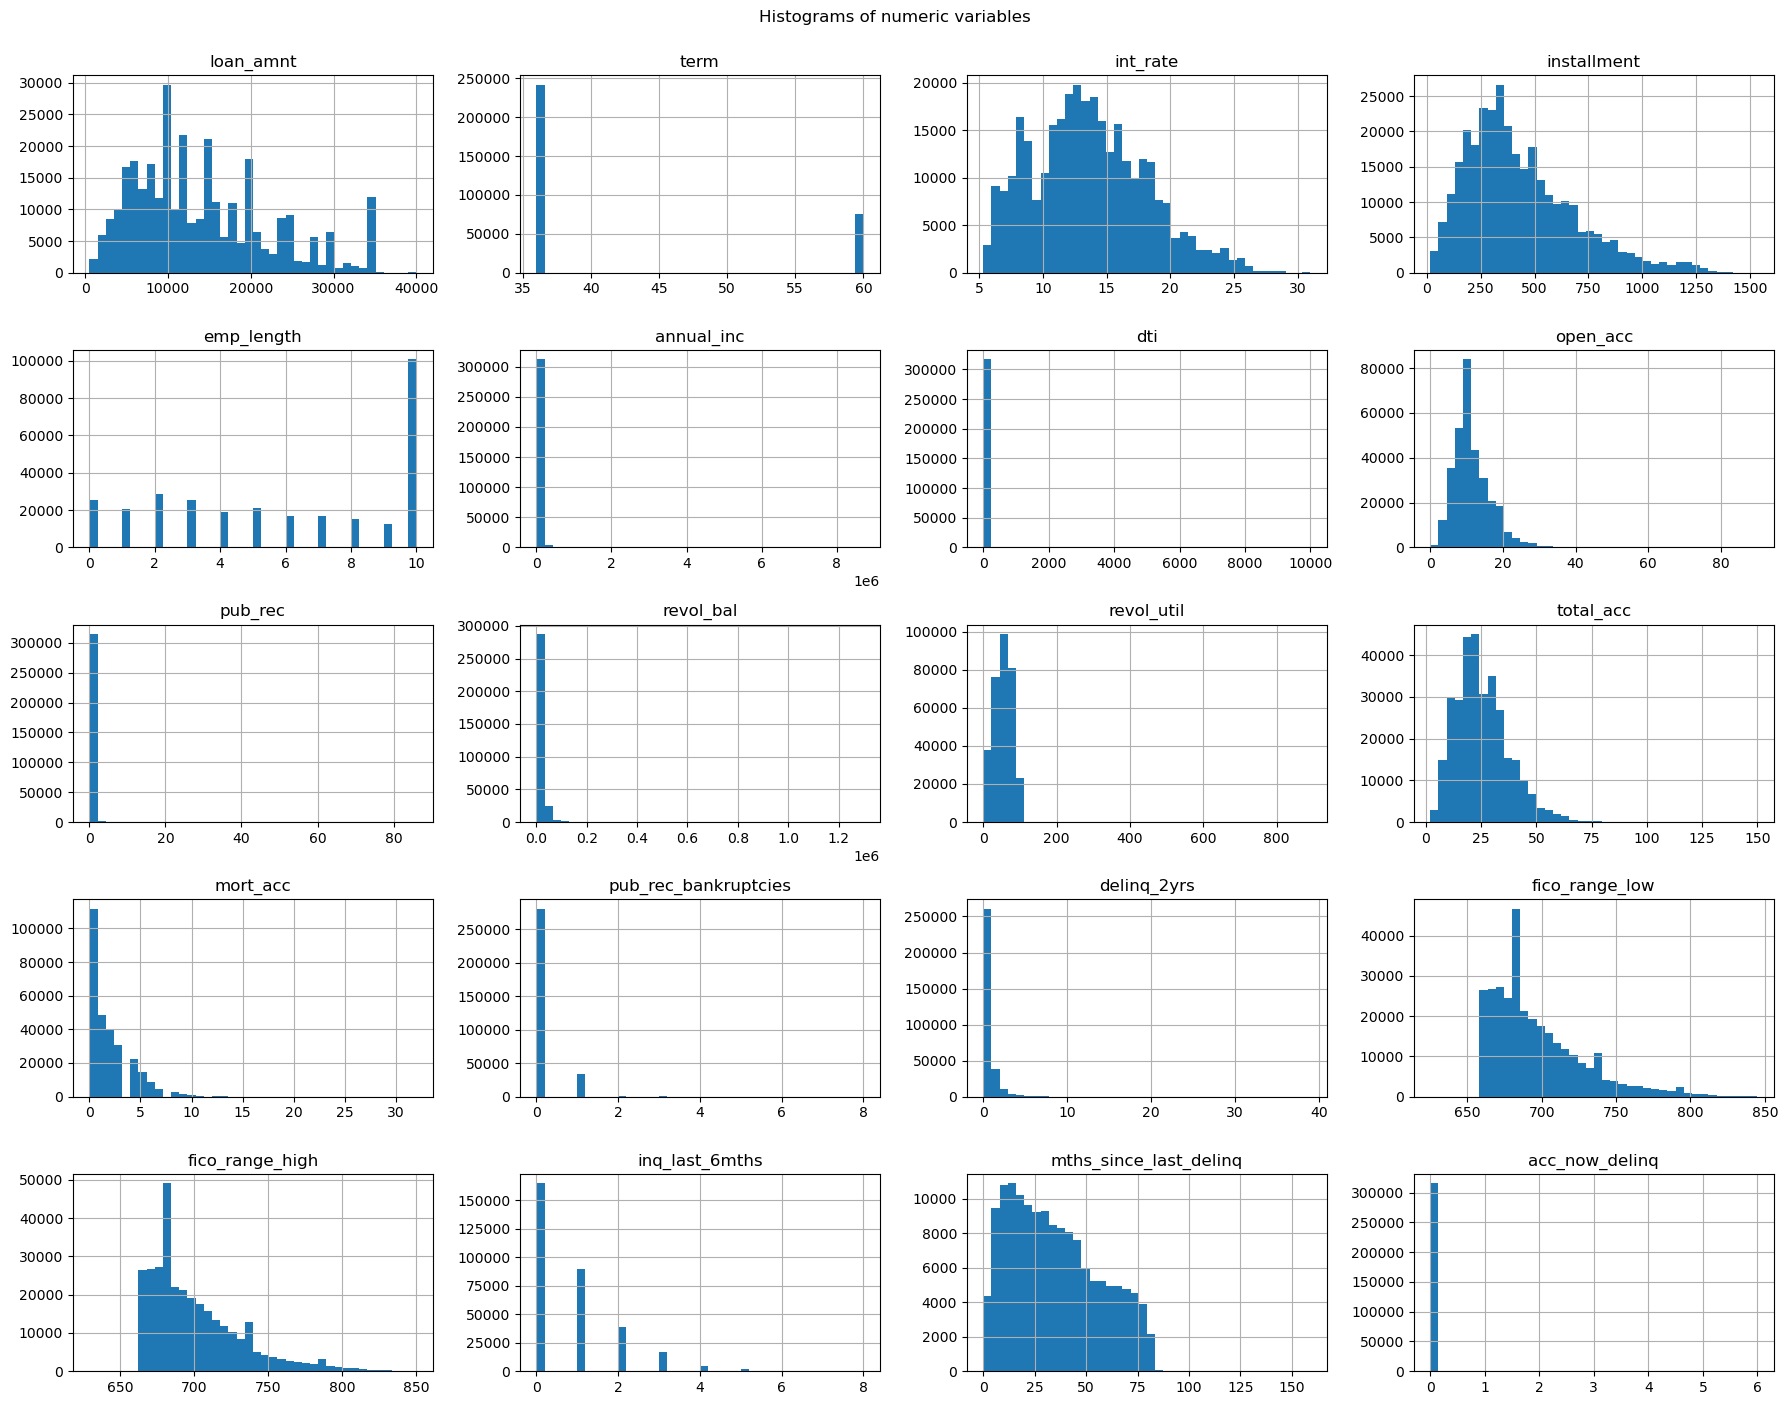

In [67]:
df[numeric_cols].hist(bins=40, figsize=(18, 14))
plt.suptitle("Histograms of numeric variables", y=1.0)
plt.tight_layout()
plt.show()


**Takeaways:** most money and count variables are **right-skewed** (`annual_inc`, `revol_bal`, `pub_rec`, `delinq_2yrs`). A few extreme values squash the rest of each histogram, which confirms the need for capping and log transforms. `int_rate`, `fico`, `dti` and `revol_util` look closer to normal.

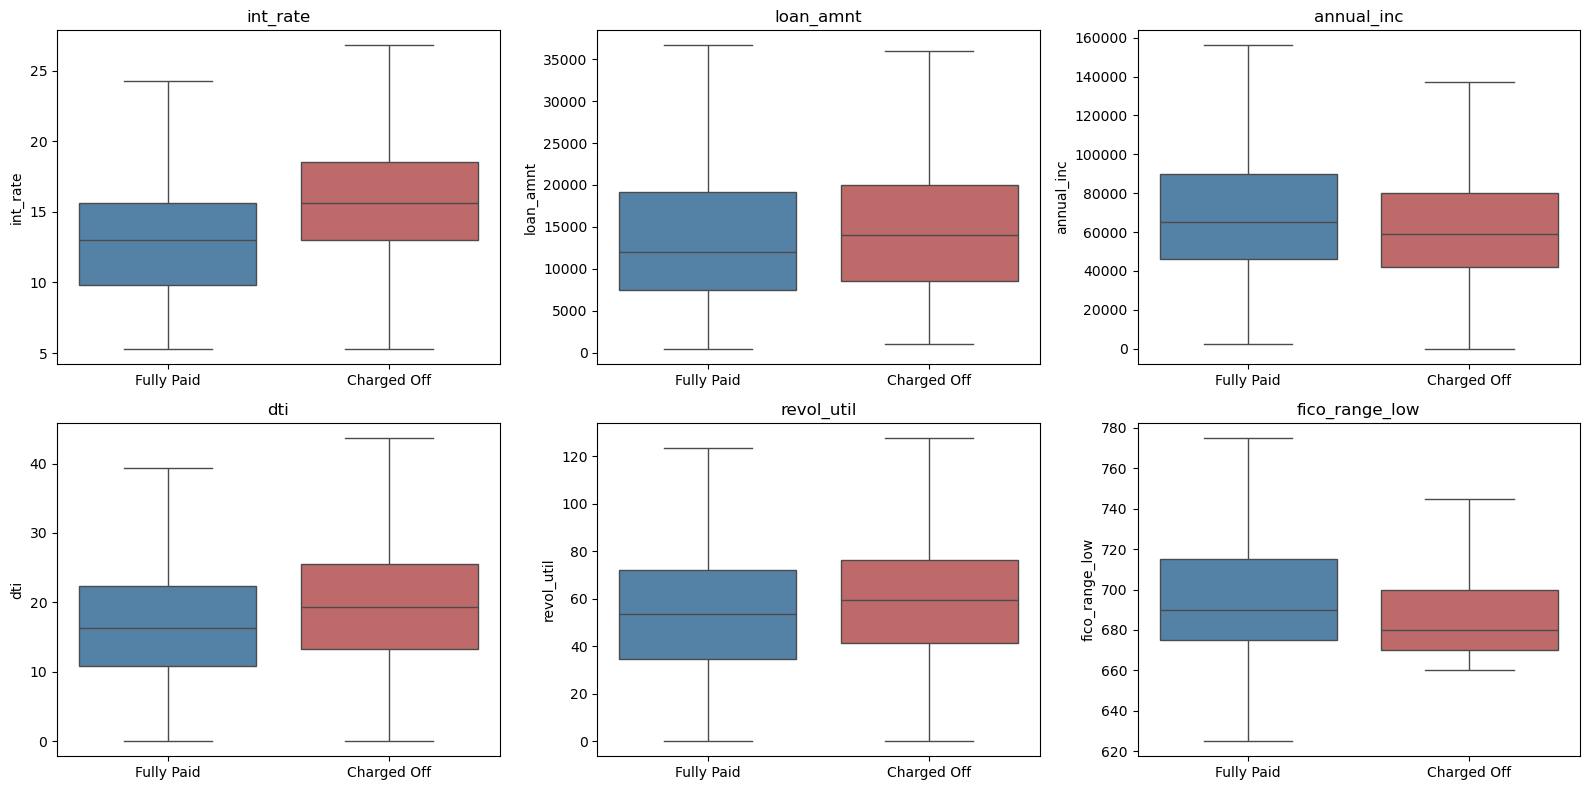

In [68]:
key_vars = ["int_rate", "loan_amnt", "annual_inc", "dti", "revol_util", "fico_range_low"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_vars):
    sns.boxplot(data=df, x="loan_status", y=col, ax=ax, showfliers=False,
                hue="loan_status", palette=["steelblue", "indianred"], legend=False)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout()
plt.show()


**Takeaways:** charged-off loans have clearly **higher interest rates** and **lower FICO scores**, plus slightly higher loan amounts, DTI and revolving utilization, and slightly lower income. Interest rate is the strongest numeric signal, which makes sense: the lender already prices risk into the rate.

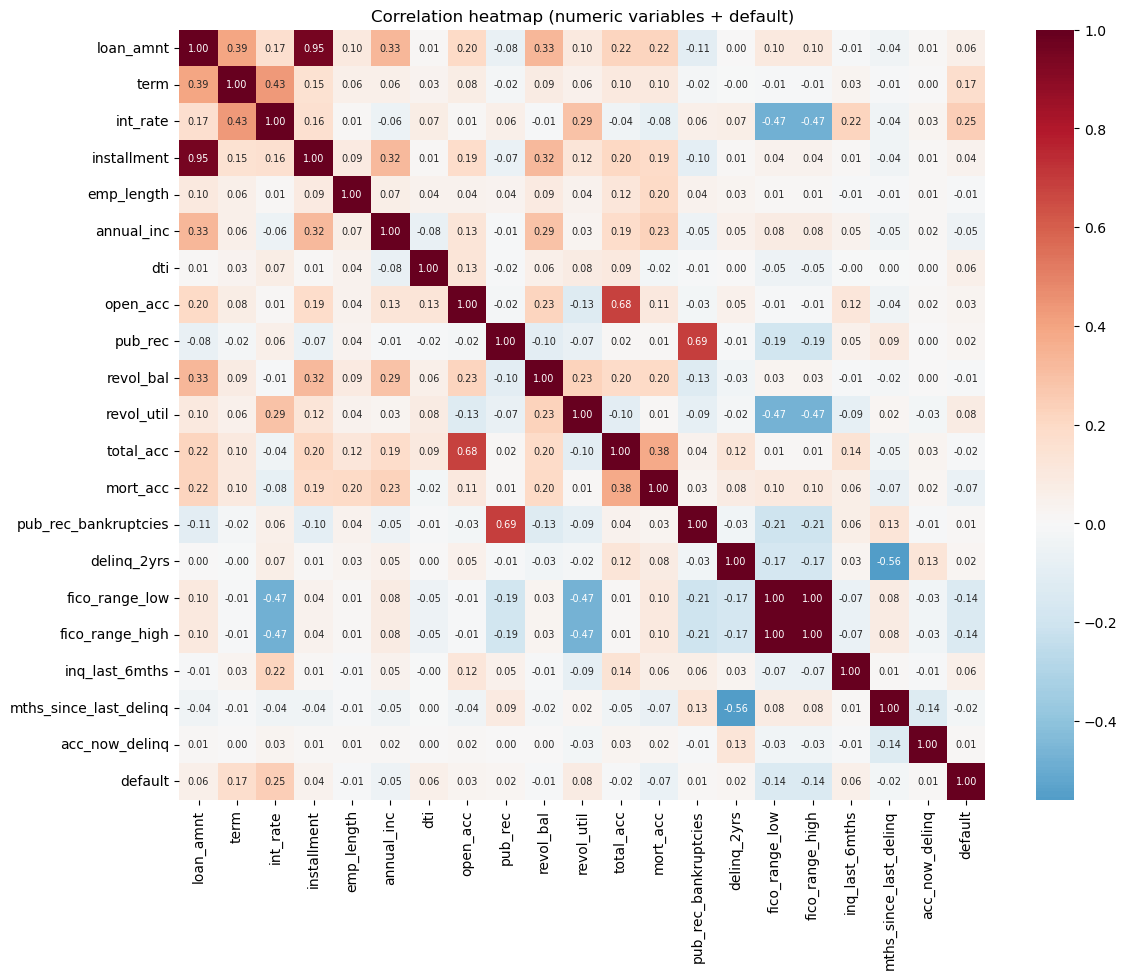

In [69]:
corr = df[list(numeric_cols) + ["default"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation heatmap (numeric variables + default)")
plt.show()

In [70]:
## Top 10 most correlated pairs of predictors (absolute value)
corr_matrix = df[numeric_cols].corr().abs()
stacked = corr_matrix.stack().sort_values(ascending=False)
most_correlated = stacked[stacked < 1].drop_duplicates().head(10)
print("Top 10 most correlated pairs (absolute value):")
display(most_correlated)

print("\nCorrelation of each numeric variable with default:")
display(corr["default"].drop("default").sort_values())

Top 10 most correlated pairs (absolute value):


fico_range_low          fico_range_high    1.0000
loan_amnt               installment        0.9539
pub_rec_bankruptcies    pub_rec            0.6929
total_acc               open_acc           0.6814
mths_since_last_delinq  delinq_2yrs        0.5594
fico_range_low          int_rate           0.4743
int_rate                fico_range_high    0.4743
revol_util              fico_range_low     0.4707
                        fico_range_high    0.4707
int_rate                term               0.4339
dtype: float64


Correlation of each numeric variable with default:


fico_range_low           -0.1411
fico_range_high          -0.1411
mort_acc                 -0.0712
annual_inc               -0.0523
mths_since_last_delinq   -0.0243
total_acc                -0.0168
emp_length               -0.0143
revol_bal                -0.0125
acc_now_delinq            0.0079
pub_rec_bankruptcies      0.0105
pub_rec                   0.0208
delinq_2yrs               0.0248
open_acc                  0.0277
installment               0.0412
dti                       0.0584
inq_last_6mths            0.0588
loan_amnt                 0.0601
revol_util                0.0830
term                      0.1736
int_rate                  0.2479
Name: default, dtype: float64

**Top correlated pairs (redundancy):**
- `fico_range_low` and `fico_range_high`: **r = 1.00** (high is always low + 4) → replace both with one `fico_avg`.
- `installment` and `loan_amnt`: **r = 0.95** (the payment is calculated from amount, rate and term) → drop `installment` and keep its information in an `installment_to_income` ratio.
- `pub_rec`/`pub_rec_bankruptcies` (0.69) and `open_acc`/`total_acc` (0.68) measure different things → keep both.

**Correlation with default:** `int_rate` (+0.25), `term` (+0.17) and FICO (−0.14) are the strongest. Everything else is weak on its own, which is why we'll create ratio and interaction features.

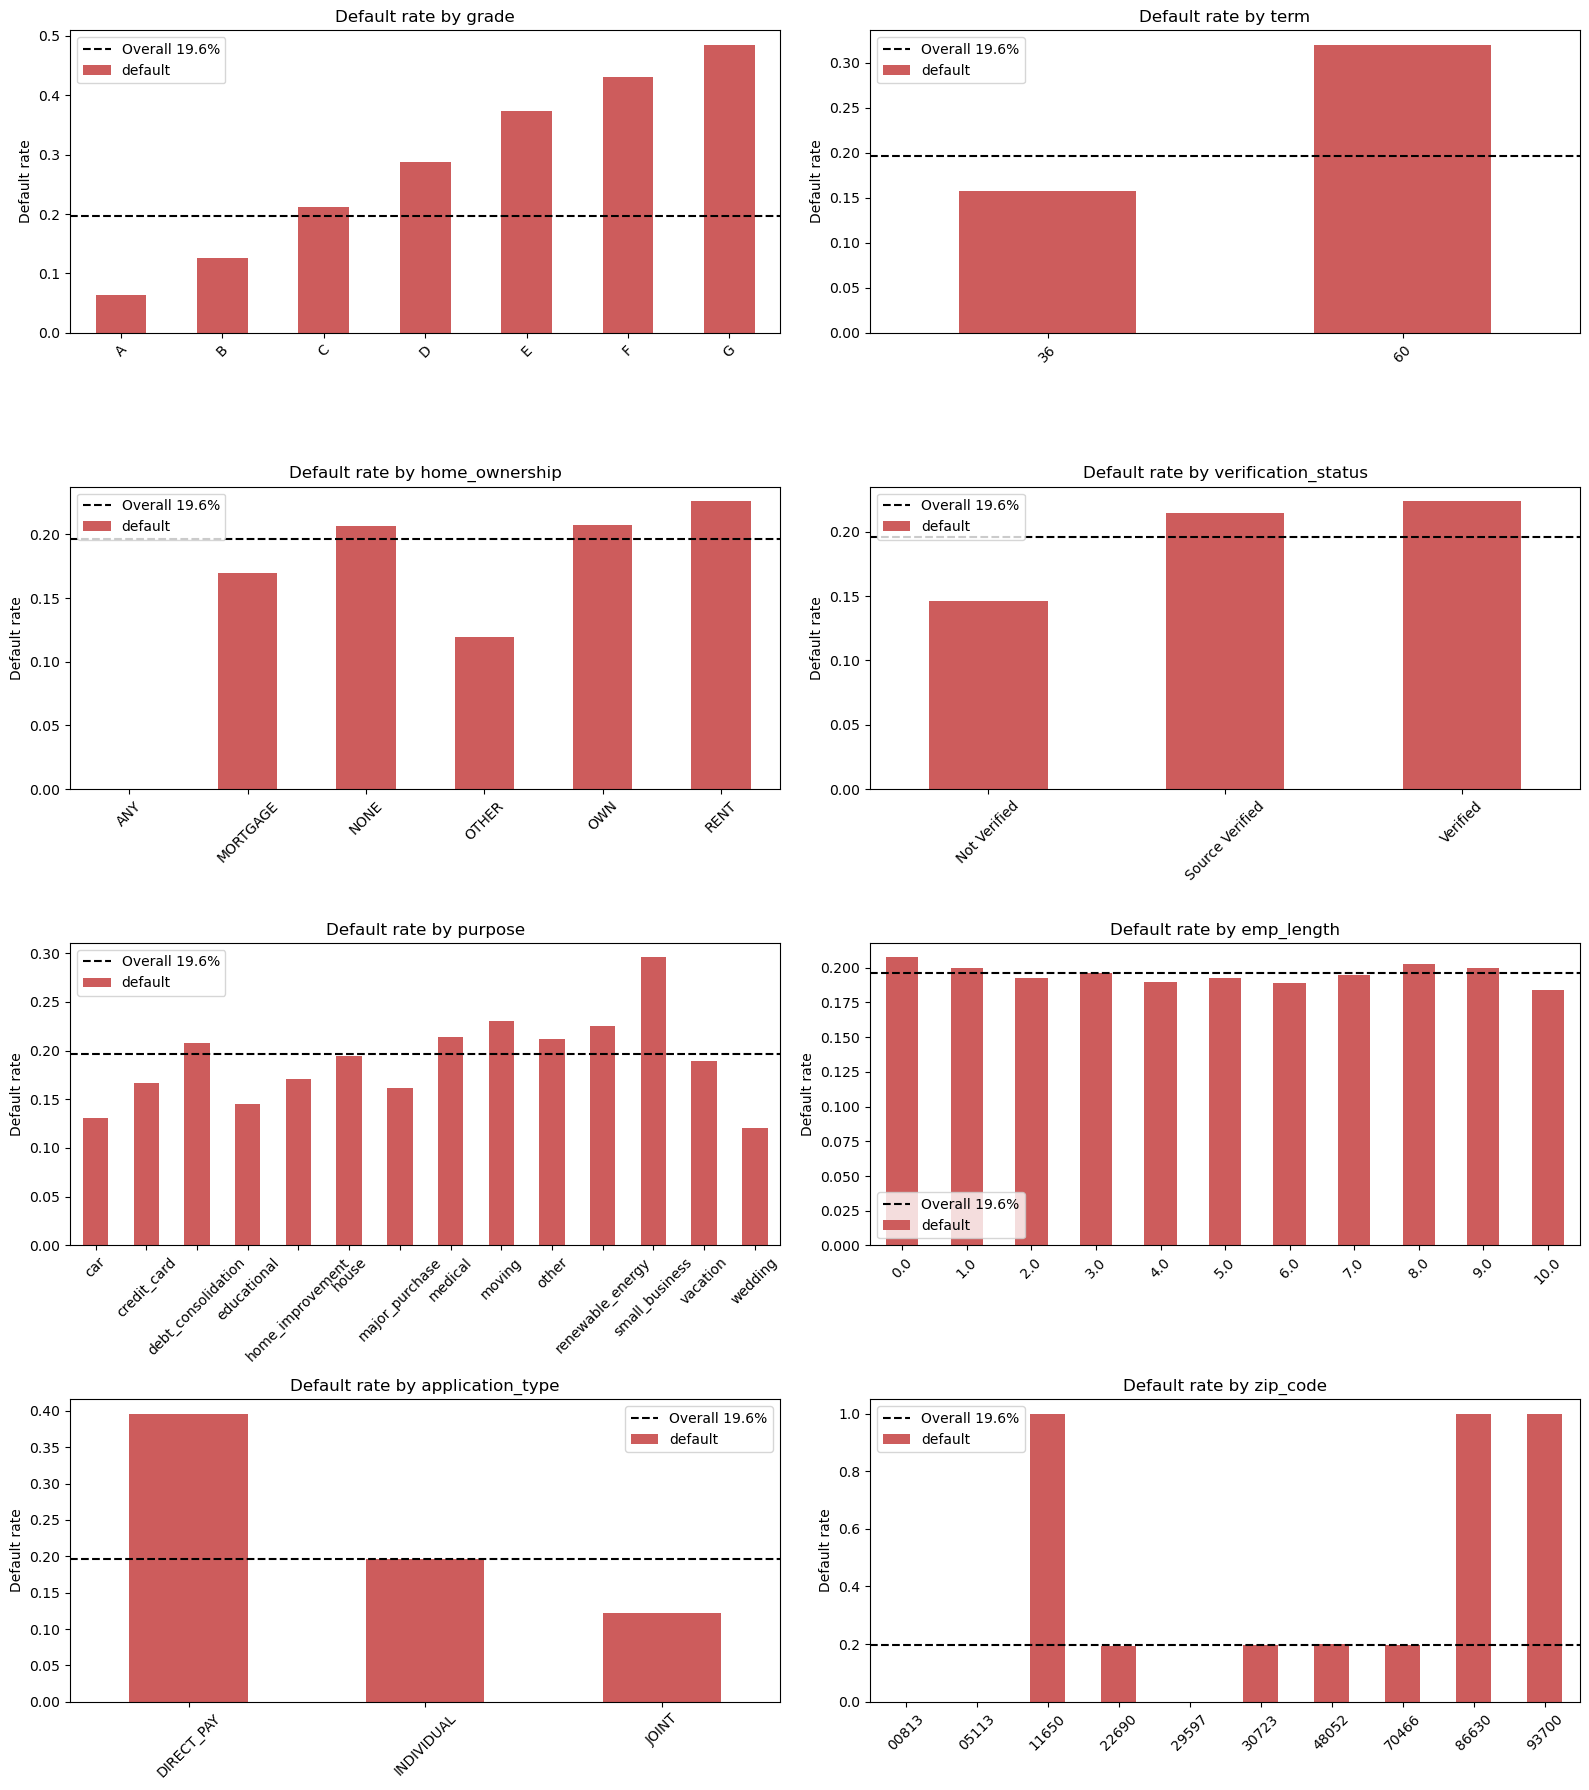

In [71]:
cat_plot_vars = ["grade", "term", "home_ownership", "verification_status",
                 "purpose", "emp_length", "application_type", "zip_code"]
overall_rate = df["default"].mean()

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for ax, col in zip(axes.ravel(), cat_plot_vars):
    rates = df.groupby(col)["default"].mean().sort_index()
    rates.plot(kind="bar", ax=ax, color="indianred")
    ax.axhline(overall_rate, color="black", linestyle="--", label=f"Overall {overall_rate:.1%}")
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("Default rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout()
plt.show()


**Takeaways:**
- **Grade** climbs steadily, from about **6% (A) to 49% (G)**. It's a very strong predictor.
- **60-month loans** default about twice as often as 36-month loans (32% vs 16%).
- **Renters** default more than mortgage holders. **Verified income** loans default *more* (the lender verifies riskier applicants).
- **Small business** is the riskiest purpose (~30%); car and wedding loans are the safest.
- `emp_length` hardly matters (18–21% across all levels).
- `DIRECT_PAY` is about 40%, but it's only 227 loans.
- **Zip code** has bars at exactly 0% and 100% (see the next cell).

In [72]:
zip_table = pd.crosstab(df["zip_code"], df["loan_status"], margins=True)
zip_table["Default rate"] = (zip_table["Charged Off"] / zip_table["All"]).round(3)
zip_table

loan_status,Charged Off,Fully Paid,All,Default rate
zip_code,,,,
00813,0,36590,36590,0.000
05113,0,36318,36318,0.000
11650,8955,0,8955,1.000
22690,8813,36510,45323,0.194
29597,0,36469,36469,0.000
30723,8902,36450,45352,0.196
48052,8972,35665,44637,0.201
70466,8896,36706,45602,0.195
86630,8709,0,8709,1.000



- 3 zip codes are **100% Charged Off** (about 8% of loans).
- 3 zip codes are **100% Fully Paid** (about 35% of loans).
- The other 4 sit right at the overall rate (~20%).

Real zip codes never separate defaults this cleanly. The street addresses are clearly fake, so this is almost certainly an **artifact of how the dataset was generated**. It's on the variable list, so it's kept for now, but it will dominate every model and inflate test accuracy.

**TO DECIDE TOGETHER:** keep it or drop it. Either way, mention it in the write-up.
**What this does:** a switch for the zip-code decision above. Leave it `True` to keep `zip_code` in the modeling data, or set it to `False` to drop it. It's used later, when we choose which columns to drop before encoding.

In [73]:
USE_ZIP = True   # set to False to exclude zip_code from the saved modeling data

In [74]:
## addr_state: is location by state informative?
state_rates = df.groupby("addr_state")["default"].agg(["mean", "size"]).sort_values("mean")
print("Number of states/territories:", len(state_rates))
print(state_rates["mean"].describe().round(3))

Number of states/territories: 54
count    54.000
mean      0.196
std       0.005
min       0.180
25%       0.193
50%       0.196
75%       0.199
max       0.210
Name: mean, dtype: float64


**What this shows:** the default rate in each state.

**Result:** 54 states/territories, and **every one sits between about 18% and 21%**, essentially the overall rate. State would add about 53 dummy columns with no signal → **drop `addr_state`** as uninformative.

# 6. Missing Data

,MissingCount,MissingFraction
mths_since_last_delinq,168727,0.5325
mort_acc,30350,0.0958
emp_title,18381,0.0580
emp_length,14656,0.0463
title,1431,0.0045
pub_rec_bankruptcies,432,0.0014
revol_util,221,0.0007


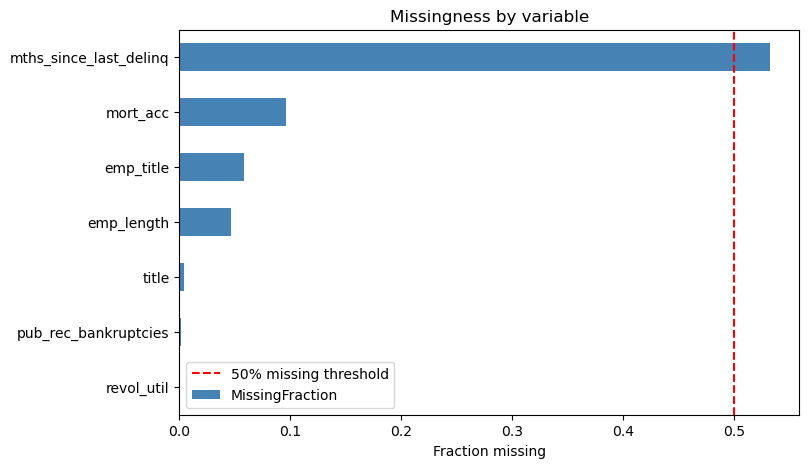

In [75]:
missing_table = pd.DataFrame({
    "MissingCount": df.isna().sum(),
    "MissingFraction": df.isna().mean()
})
missing_table = missing_table[missing_table["MissingCount"] > 0].sort_values("MissingFraction", ascending=False)
display(missing_table)

missing_table["MissingFraction"].sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.axvline(0.50, color="red", linestyle="--", label="50% missing threshold")
plt.xlabel("Fraction missing"); plt.title("Missingness by variable"); plt.legend()
plt.show()

In [76]:
rows = []
for col in missing_table.index:
    is_missing = df[col].isna()
    rows.append({"Variable": col,
                 "Default rate | missing": df.loc[is_missing, "default"].mean(),
                 "Default rate | present": df.loc[~is_missing, "default"].mean()})
pd.DataFrame(rows).set_index("Variable").round(3)

,Default rate | missing,Default rate | present
Variable,,
mths_since_last_delinq,0.190,0.203
mort_acc,0.146,0.201
emp_title,0.262,0.192
emp_length,0.278,0.192
title,0.179,0.196
pub_rec_bankruptcies,0.181,0.196
revol_util,0.222,0.196



**Results:**
- Missing `emp_title` or `emp_length` → about **26–28% default** vs 19% when present. Not reporting employment is a risk signal.
- Missing `mort_acc` → about 15% vs 20%.
- Missing `mths_since_last_delinq` → about 19% vs 20%.



# 7. Outliers and Impossible Values

In [77]:
## IQR rule: count potential outliers per numeric variable
num_check = df[numeric_cols]
Q1, Q3 = num_check.quantile(0.25), num_check.quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((num_check < Q1 - 1.5 * IQR) | (num_check > Q3 + 1.5 * IQR)).sum()
outlier_counts.sort_values(ascending=False).to_frame("IQR outliers").head(12)

,IQR outliers
term,75056
delinq_2yrs,55999
pub_rec,46177
pub_rec_bankruptcies,36057
inq_last_6mths,23192
revol_bal,17036
annual_inc,13329
fico_range_high,10826
fico_range_low,10826
installment,8968


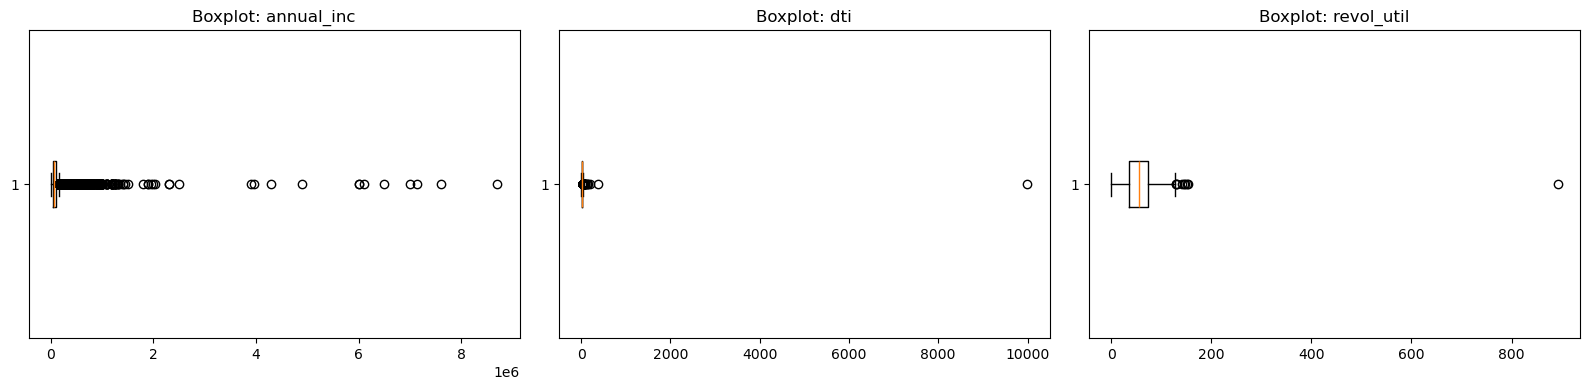

dti > 100: 6 -> [120.66, 138.03, 145.65, 189.9, 380.53, 9999.0]
annual_inc == 0: 1
revol_util > 150: 3 -> [150.7, 153.0, 892.3]
annual_inc 99th / 99.9th percentile: [250000.0, 525000.0]


In [78]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["annual_inc", "dti", "revol_util"]):
    a.boxplot(df[col].dropna(), vert=False)
    a.set_title(f"Boxplot: {col}")
plt.tight_layout(); plt.show()

print("dti > 100:", (df["dti"] > 100).sum(), "->", sorted(df.loc[df["dti"] > 100, "dti"].unique()))
print("annual_inc == 0:", (df["annual_inc"] == 0).sum())
print("revol_util > 150:", (df["revol_util"] > 150).sum(), "->", sorted(df.loc[df["revol_util"] > 150, "revol_util"].unique()))
print("annual_inc 99th / 99.9th percentile:", df["annual_inc"].quantile([0.99, 0.999]).tolist())


**Results and decisions:**
- `dti > 100`: 6 loans (e.g., **9,999**) → impossible → set to missing.
- `annual_inc == 0`: 1 loan → a $0 income can't produce a DTI → set to missing.
- `revol_util > 150`: 3 loans (e.g., **892%**) → set to missing.
- High incomes (99.9th percentile ≈ $525k) are **extreme but possible** → keep them, then cap at the training set's 99.9th percentile and log-transform later. We don't delete them.

In [79]:
df.loc[df["dti"] > 100, "dti"] = np.nan
df.loc[df["annual_inc"] == 0, "annual_inc"] = np.nan
df.loc[df["revol_util"] > 150, "revol_util"] = np.nan
print(df[["dti", "annual_inc", "revol_util"]].isna().sum())

dti             6
annual_inc      1
revol_util    224
dtype: int64
